In [61]:
import torch
import matplotlib.pyplot as plt
import matplotx
from matplotlib.colors import PowerNorm, LinearSegmentedColormap
plt.style.use(matplotx.styles.github['dark'])

In [80]:
# CONSTANTS
SEED = 2147483647
ALPHA = 50

In [3]:
words = open("names.txt", 'r').read().splitlines()

In [4]:
len(words), min(len(w) for w in words), max(len(w) for w in words)

(32033, 2, 15)

In [5]:
# bigrams
b = {}
for w in words:
    w = ["<S>"] + list(w) + ["<E>"]
    for ch1, ch2 in zip(w, w[1:]):
        b[(ch1, ch2)] = b.get((ch1, ch2), 0) + 1
sorted(b.items(), key= lambda x : -x[1])

[(('n', '<E>'), 6763),
 (('a', '<E>'), 6640),
 (('a', 'n'), 5438),
 (('<S>', 'a'), 4410),
 (('e', '<E>'), 3983),
 (('a', 'r'), 3264),
 (('e', 'l'), 3248),
 (('r', 'i'), 3033),
 (('n', 'a'), 2977),
 (('<S>', 'k'), 2963),
 (('l', 'e'), 2921),
 (('e', 'n'), 2675),
 (('l', 'a'), 2623),
 (('m', 'a'), 2590),
 (('<S>', 'm'), 2538),
 (('a', 'l'), 2528),
 (('i', '<E>'), 2489),
 (('l', 'i'), 2480),
 (('i', 'a'), 2445),
 (('<S>', 'j'), 2422),
 (('o', 'n'), 2411),
 (('h', '<E>'), 2409),
 (('r', 'a'), 2356),
 (('a', 'h'), 2332),
 (('h', 'a'), 2244),
 (('y', 'a'), 2143),
 (('i', 'n'), 2126),
 (('<S>', 's'), 2055),
 (('a', 'y'), 2050),
 (('y', '<E>'), 2007),
 (('e', 'r'), 1958),
 (('n', 'n'), 1906),
 (('y', 'n'), 1826),
 (('k', 'a'), 1731),
 (('n', 'i'), 1725),
 (('r', 'e'), 1697),
 (('<S>', 'd'), 1690),
 (('i', 'e'), 1653),
 (('a', 'i'), 1650),
 (('<S>', 'r'), 1639),
 (('a', 'm'), 1634),
 (('l', 'y'), 1588),
 (('<S>', 'l'), 1572),
 (('<S>', 'c'), 1542),
 (('<S>', 'e'), 1531),
 (('j', 'a'), 1473),
 (

In [6]:
N = torch.zeros((27, 27), dtype = torch.int32)

In [7]:
chars = sorted(list(set(''.join(words))))

ctoi = {c:i+1 for i, c in enumerate(chars)};
ctoi['.'] = 0
itoc = {i:s for s, i in ctoi.items()}

In [8]:
for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        idx1 = ctoi[ch1]
        idx2 = ctoi[ch2]
        N[idx1, idx2] += 1

In [9]:
# normalize
P = N.float()
P /= P.sum(1, keepdim=True)

### Please note that the codeblock below is mainly for normalized values

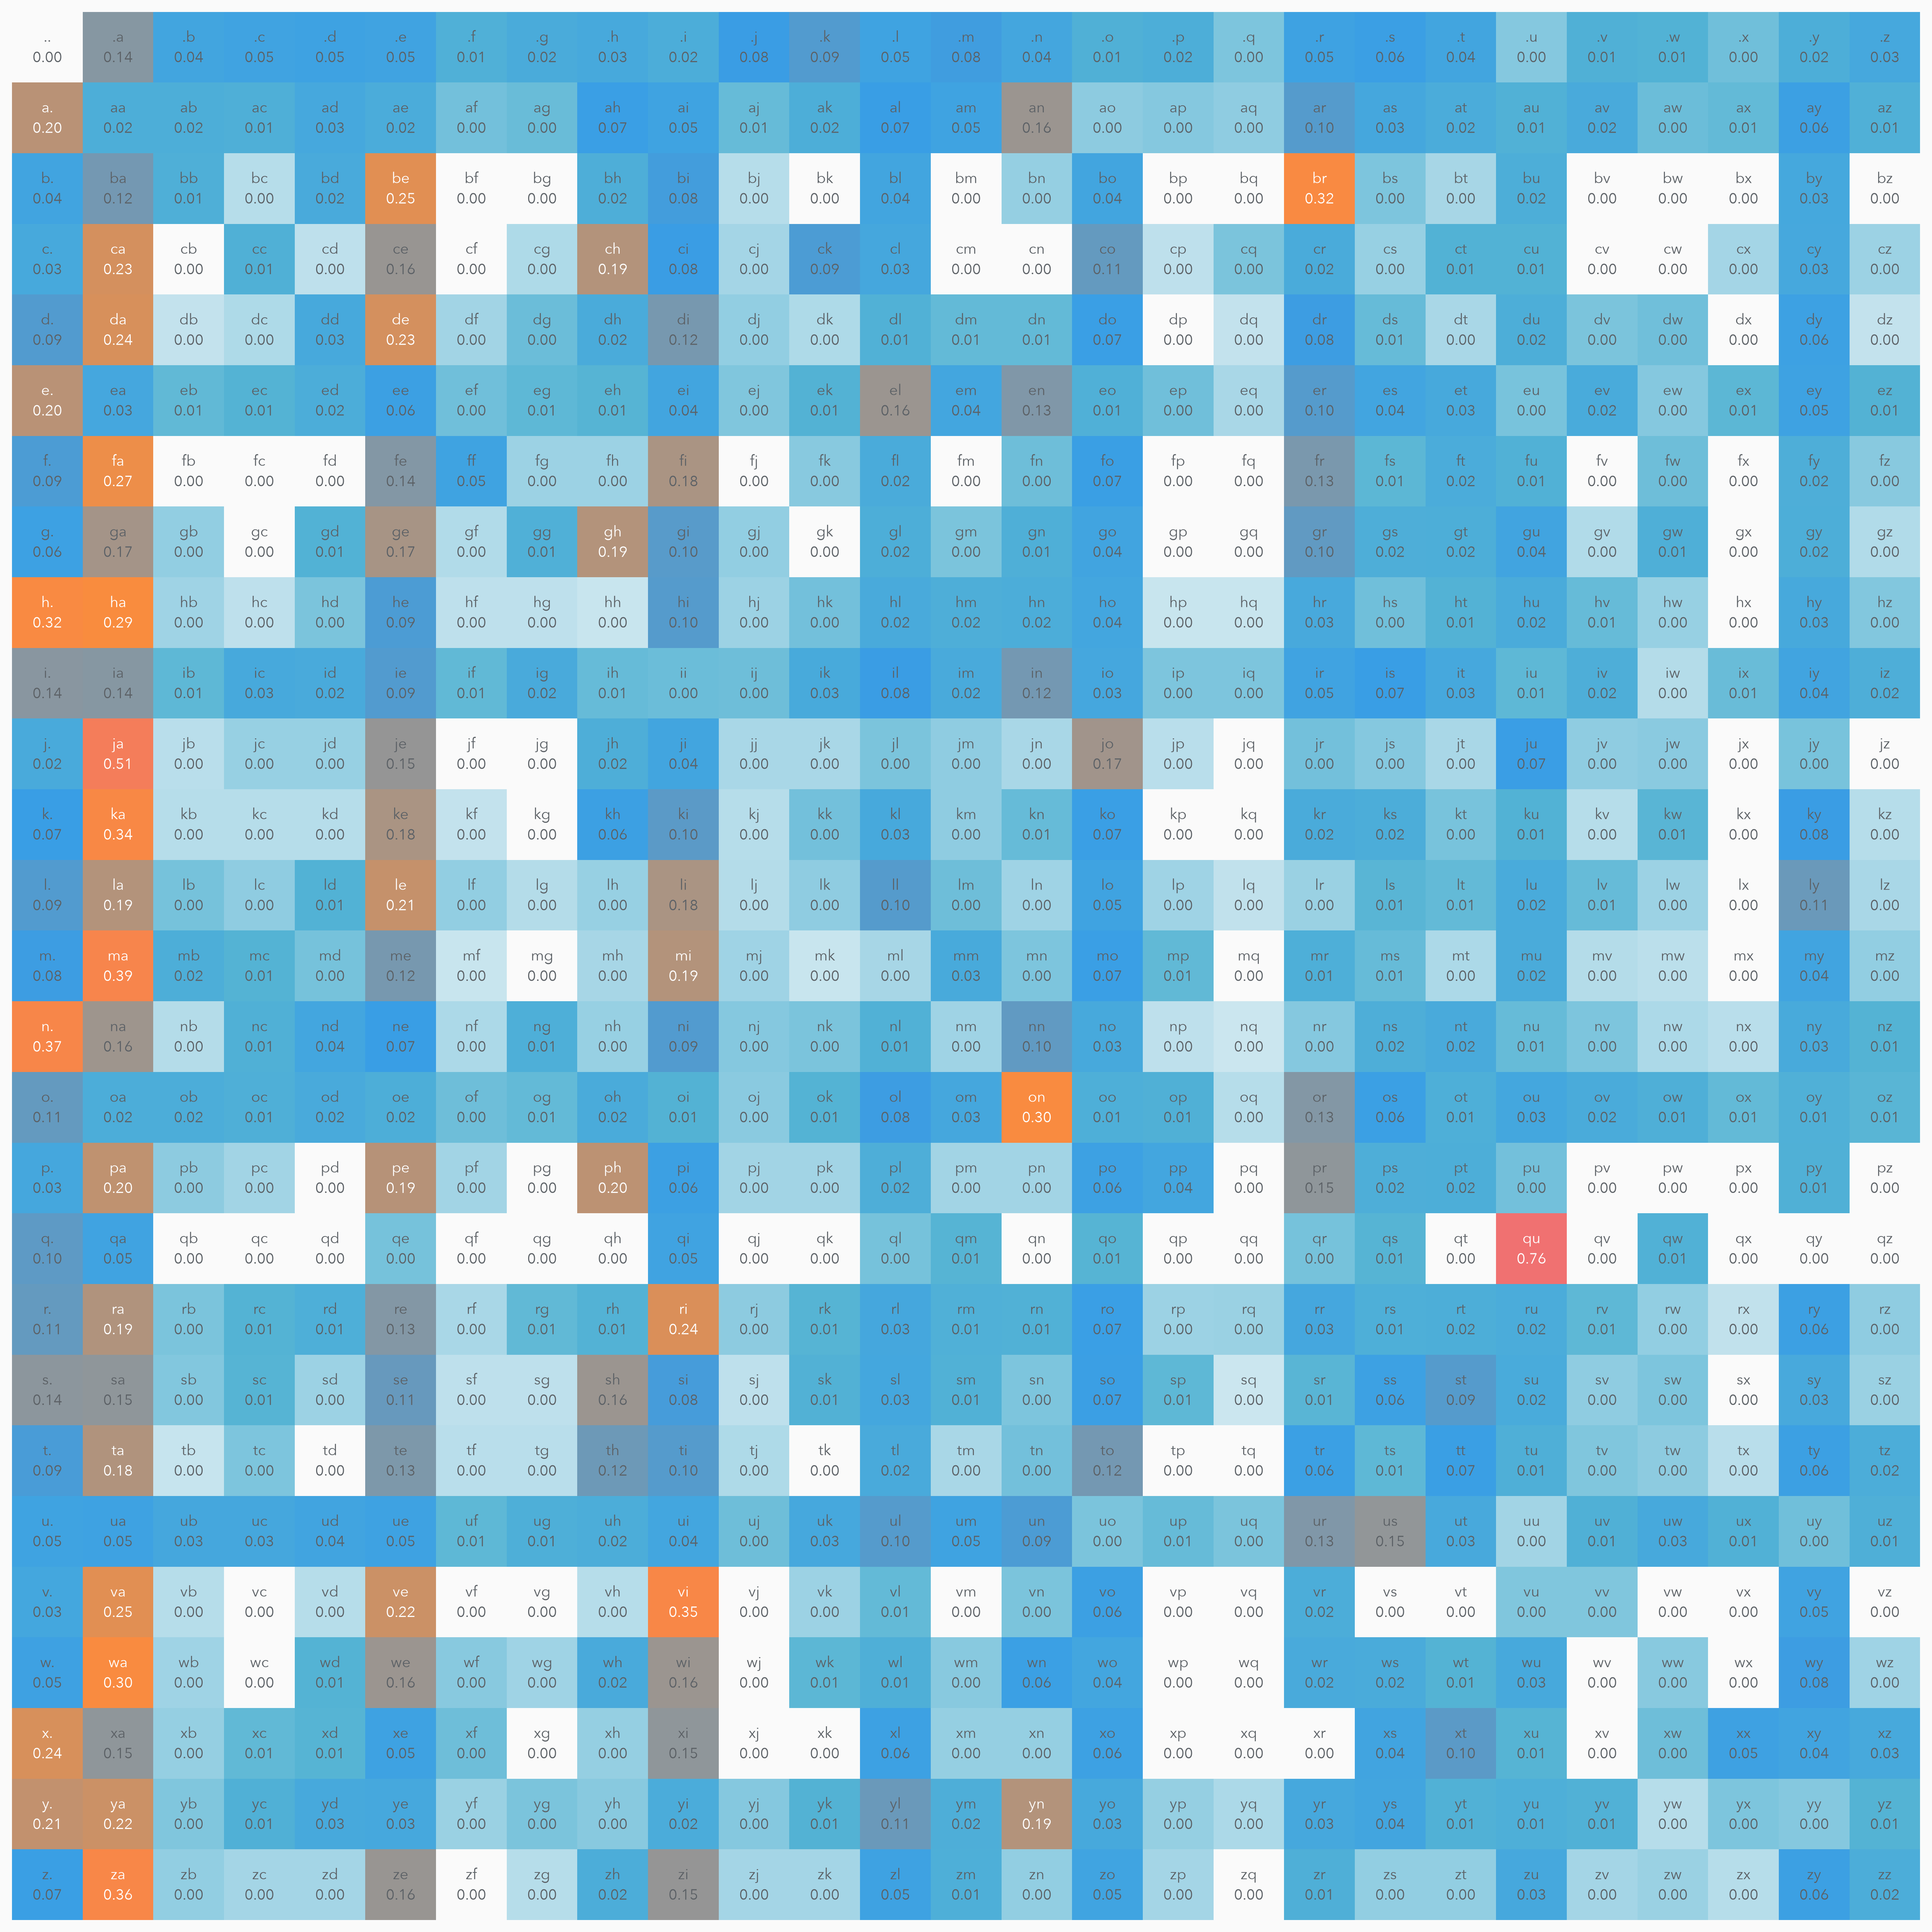

In [10]:
norm = PowerNorm(gamma=0.3, vmin=0, vmax=P.max().item())

bg, fg = '#FAFAFA', '#5C6166'
ayu = LinearSegmentedColormap.from_list(
    'ayu_light', [bg, '#55B4D4', '#399EE6', '#FA8D3E', '#F07171']
)

fig = plt.figure(figsize=(16,16), facecolor=bg)
plt.imshow(P.numpy(), cmap=ayu, norm=norm)
for i in range(27):
    for j in range(27):
        v = P[i, j].item()
        c = 'white' if norm(v) > 0.65 else fg
        plt.text(j, i, itoc[i] + itoc[j], ha="center", va="bottom", color=c, fontsize=9)
        plt.text(j, i, f"{v:.2f}", ha="center", va="top", color=c, fontsize=9)
plt.axis('off');

In [11]:
g = torch.Generator().manual_seed(SEED)

for i in range(10):
    idx = 0
    string = ""
    while True:
        p = P[idx]
        idx = torch.multinomial(p, num_samples = 1, replacement = True, generator = g).item()
        string += itoc[idx]
        if idx == 0: break
    print(string)

cexze.
momasurailezitynn.
konimittain.
llayn.
ka.
da.
staiyaubrtthrigotai.
moliellavo.
ke.
teda.


In [47]:
# maximum likelihood estimation
# maximizing prob = maximizing log prob = minimizing -ve log prob

log_likelihood = 0.0
n = 0
for w in ["emily"]:
    w = ['.'] + list(w) + ['.']
    for c1, c2 in zip(w, w[1:]):
        idx1 = ctoi[c1]
        idx2 = ctoi[c2]
        p = P[idx1, idx2]
        log_prob = torch.log(p)
        log_likelihood += log_prob
        n += 1
        print(f"{c1}{c2}: {p:.4f} {log_prob:.4f}")

nll = -log_likelihood
print(f"negative log likelihood (loss): {nll}")

.e: 0.0478 -3.0408
em: 0.0377 -3.2793
mi: 0.1891 -1.6655
il: 0.0760 -2.5772
ly: 0.1138 -2.1736
y.: 0.2053 -1.5833
negative log likelihood (loss): 14.319746017456055


In [48]:
from graphviz import Digraph

# visual-only: these classes hold labels and shapes, no weights or math
class VizNeuron:
    def __init__(self, label=''):
        self.label = label

class VizLayer:
    def __init__(self, n, d=None, label='', bias=True):
        # d = weights per neuron (inputs from the previous layer); None for the input layer
        self.label = label
        self.d = d
        self.bias = bias
        self.neurons = [VizNeuron(f'{i}') for i in range(n)]

    def info(self):
        n = len(self.neurons)
        if self.d is None:
            return [f'{n} inputs']
        lines = [f'{n} neurons', f'{self.d} weights each', f'W: ({self.d}, {n})']
        if self.bias: lines.append(f'b: ({n},)')
        lines.append(f'{self.n_params()} params')
        return lines

    def n_params(self):
        n = len(self.neurons)
        return 0 if self.d is None else n * self.d + (n if self.bias else 0)

class VizNetwork:
    # same shape args as MultiLayerPerceptron: input size, then neurons per layer
    def __init__(self, input_dim: int, neuron_layers: list[int], bias=True):
        info = [input_dim] + neuron_layers
        self.layers = [VizLayer(input_dim, label='input')]
        self.layers += [VizLayer(info[i + 1], info[i], label=f'layer {i}', bias=bias) for i in range(len(neuron_layers))]

    def draw(self, max_shown=10):
        # layers with more than max_shown neurons show only the first/last few, with ⋮ and a count in between
        # max_shown=None draws every neuron
        colors = {
            'input':  ('#DCEBFA', '#5B9BD5'),
            'hidden': ('#FDE7D4', '#E8914A'),
            'output': ('#E3F4E1', '#5DAE5A'),
        }
        col_gap, row_gap = 2.6, 0.42

        dot = Digraph(engine='neato', format='svg')
        dot.attr(bgcolor='white', splines='false', overlap='true', outputorder='edgesfirst')
        dot.attr('node', shape='circle', fixedsize='true', width='0.34', style='filled',
                 fontname='Helvetica', fontsize='9', fontcolor='#3A3F44', penwidth='1.2')
        dot.attr('edge', color='#AEB8C266', penwidth='0.6', arrowhead='none')

        def shown(layer):
            # which neuron indices get a node; None marks the ⋮ slot
            n = len(layer.neurons)
            if max_shown is None or n <= max_shown:
                return list(range(n))
            k = max_shown // 2
            return list(range(k)) + [None] + list(range(n - (max_shown - k), n))

        def slots(col):
            # the ⋮ block takes 3 rows so its count has room
            return sum(3 if ni is None else 1 for ni in col)

        columns = [shown(l) for l in self.layers]
        top = max(slots(c) for c in columns) * row_gap / 2 + 0.75

        for li, (layer, col) in enumerate(zip(self.layers, columns)):
            kind = 'input' if li == 0 else 'output' if li == len(self.layers) - 1 else 'hidden'
            fill, line = colors[kind]
            x = li * col_gap
            y = (slots(col) - 1) * row_gap / 2

            for ni in col:
                if ni is None:
                    y -= row_gap  # center of the 3-row block
                    hidden = len(layer.neurons) - (len(col) - 1)
                    dot.node(f'L{li}_more',
                             f'<⋮<br/><b>+{hidden} more</b><br/><font point-size="8">{len(layer.neurons)} total</font><br/>⋮>',
                             pos=f'{x},{y}!', shape='plaintext', style='', fixedsize='false',
                             fontcolor=line, fontsize='9')
                    y -= 2 * row_gap
                else:
                    dot.node(f'L{li}_N{ni}', layer.neurons[ni].label, pos=f'{x},{y}!', fillcolor=fill, color=line)
                    y -= row_gap

            # header card above each column, bottoms lined up (neato places nodes by their center)
            title = f'<b>{layer.label}</b>'
            lines = layer.info()
            body = '<br/>'.join(lines)
            dot.node(f'L{li}_info', f'<{title}<br/><font point-size="9" color="#6B737B">{body}</font>>',
                     pos=f'{x},{top + (len(lines) + 1) * 0.075}!', shape='box', style='rounded,filled', fillcolor=fill, color=line,
                     fixedsize='false', fontsize='10', margin='0.12,0.06')

        # wires: every neuron in layer i feeds every neuron in layer i + 1
        # dashed, fainter wires stand in for the ones going to/from the collapsed neurons
        name = lambda li, ni: f'L{li}_more' if ni is None else f'L{li}_N{ni}'
        for li in range(len(self.layers) - 1):
            for a in columns[li]:
                for b in columns[li + 1]:
                    if a is None or b is None:
                        dot.edge(name(li, a), name(li + 1, b), style='dashed', color='#AEB8C240')
                    else:
                        dot.edge(name(li, a), name(li + 1, b))

        total = sum(l.n_params() for l in self.layers)
        dot.attr(label=f'total params: {total}', labelloc='b', fontname='Helvetica',
                 fontsize='10', fontcolor='#6B737B')
        return dot

In [81]:
g = torch.Generator().manual_seed(SEED)
W0 = torch.randn((27, 27), generator= g, requires_grad= True)
# get bigrams setup
xs = []
ys = []
for w in words:
    w = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(w, w[1:]):
        idx1 = ctoi[ch1] # current char
        idx2 = ctoi[ch2] # expected
        #print(f"bigram: {ch1}{ch2}: ({idx1}, {idx2})")

        xs.append(idx1)
        ys.append(idx2)
n = len(xs)
#print("bigram count:", n)
xs = torch.tensor(xs)
ys = torch.tensor(ys)
xenc = torch.nn.functional.one_hot(xs, num_classes= 27).float() # (bigram_count, 27)

In [82]:
'''
Notes:
- Takes n examples and does forward pass.
'''
def forward():
    logits = xenc @ W0 # (bigram_count, 27) * (27, 27) = (bigram_count, 27)
    ycounts = logits.exp()
    probs = ycounts / ycounts.sum(1, keepdim= True)

    # vectorized loss
    loss = -probs[torch.arange(n), ys].log().mean()
    #print(f"-ve log likelihood loss: {loss}")
    return loss

def backward(loss: torch.Tensor):
    W0.grad = None
    loss.backward()
    W0.data += -ALPHA * W0.grad

def full(epoch = 1):
    losses = []
    for _ in range(epoch):
        loss = forward()
        losses.append(loss)
        backward(loss)
    return torch.tensor(losses)

# purely made to predict a name.
def predict(prediction_counts=1):
    for _ in range(prediction_counts):
        out = []
        ix = 0
        while True:
            xs = torch.tensor([ix])
            enc = torch.nn.functional.one_hot(xs, num_classes= 27).float() # (1, 27)
            yout = enc @ W0 # (1, 27) * (27, 27) -> (1, 27)
            ycount = yout.exp()
            yprob = ycount / ycount.sum(1, keepdim= True)
            # multinomial
            ix = torch.multinomial(yprob, num_samples= 1, replacement= True, generator= g).item()
            out.append(itoc[ix])
            if ix == 0: break
        print(''.join(out))

In [83]:
losses = full(1000)
print(losses[-1])

tensor(2.4554)


In [87]:
predict(10)

erie.
iabentabenele.
hvemyli.
wt.
kazan.
ldalaigiashadinn.
calis.
ayriyeiamiarkrahriraivesari.
janeellien.
deamin.
